# Assignment 2 - Causal Inference

I use the same dataset as in Assignment 1 (414 house sales, price per unit area as the target), so I don't re-analyse the data here.

In Assignment 1, the distance to the nearest MRT station had the strongest correlation with price (-0.72, and -0.78 with the log). But a correlation doesn't show that being close to a station causes a higher price, because houses near stations are also different in other ways (more central, more convenience stores nearby, etc.).

The question here: if a house was moved next to an MRT station and everything else stayed the same, how much would its price per unit area change?

I first use CausalML (LRSRegressor and XGBTRegressor) and then DoWhy.

# 0. Setup

Before running the notebook, I created a Python 3.12 virtual environment and installed the libraries with pip install pandas numpy matplotlib scikit-learn openpyxl causalml dowhy xgboost notebook ipykernel. I also had to install older versions of pandas, networkx and pydot (pip install "pandas<3" "networkx<3.5" "pydot<4"), because the DoWhy version that works with causalml on Python 3.12 doesn't work with the newest versions of these. The cell below prints the versions I used:

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from importlib.metadata import version
for pkg in ["causalml", "dowhy", "xgboost", "scikit-learn", "pandas"]:
    print(f"{pkg:13s}", version(pkg))

causalml      0.18.0
dowhy         0.12
xgboost       3.4.1
scikit-learn  1.9.1
pandas        2.3.3


# 1. Data Acquisition

In [2]:
df = pd.read_excel("Real_estate_valuation_data_set.xlsx")
df.columns = ["No", "Date", "Age", "MRT_distance", "Stores", "Lat", "Lon", "Price"]
df = df.drop(columns="No")
df.head()

,Date,Age,MRT_distance,Stores,Lat,Lon,Price
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


I use the same column names as in Assignment 1. Here I keep all 414 houses (no train/test split), since the goal is to estimate an effect, not to test predictions on new houses. The CausalML example notebooks also use the full data.

# 2. Target, Treatment and Control Features

- Target: 'Price'
- Treatment: 'near_MRT' = 1 if the house is less than 500 m from a station, 0 otherwise. The meta-learners need a binary treatment. I chose 500 m because it was already one of my 'MRT_cat' bins in Assignment 1, and it is close to the median distance (about 492 m), so both groups have about the same size.
- Controls: 'Date', 'Age', 'Stores', 'Lat', 'Lon' -> these can affect both whether a house is near a station and its price.

One problem with 'Stores': convenience stores probably open around stations, so the number of stores could partly be a result of being near the MRT, and not only a cause. If that's true, controlling for 'Stores' removes part of the station effect. I keep it as a control in the main analysis, and I check what happens without it later (3.5 and 4.6).

In [3]:
df["near_MRT"] = (df["MRT_distance"] < 500).astype(int)

treatment = "near_MRT"
outcome = "Price"
controls = ["Date", "Age", "Stores", "Lat", "Lon"]

df[treatment].value_counts()

near_MRT
1    211
0    203
Name: count, dtype: int64

In [4]:
print(f"Median distance to MRT: {df['MRT_distance'].median():.0f} m")

Median distance to MRT: 492 m


In [5]:
# Comparing the two groups before any adjustment
df.groupby(treatment)[[outcome] + controls].mean().round(3)

,Price,Date,Age,Stores,Lat,Lon
near_MRT,,,,,,
0,29.397,2013.170,18.721,2.207,24.965,121.526
1,46.238,2013.129,16.743,5.910,24.973,121.540


In [6]:
naive_diff = df.loc[df[treatment] == 1, outcome].mean() - df.loc[df[treatment] == 0, outcome].mean()
print(f"Naive difference in mean price (near - far): {naive_diff:.2f}")

Naive difference in mean price (near - far): 16.84


The naive difference is 16.8, but the 2 groups are not really comparable -> houses near a station have a lot more stores nearby (5.9 vs 2.2 on average) and they are more north and east, which is the expensive cluster from the Assignment 1 map. So part of this difference comes from these other factors and not from the station.

#### Overlap check

To compare the groups, there need to be both near and far houses for each type of house. I check this with a propensity score (the probability of being near a station given the controls), using a logistic regression.

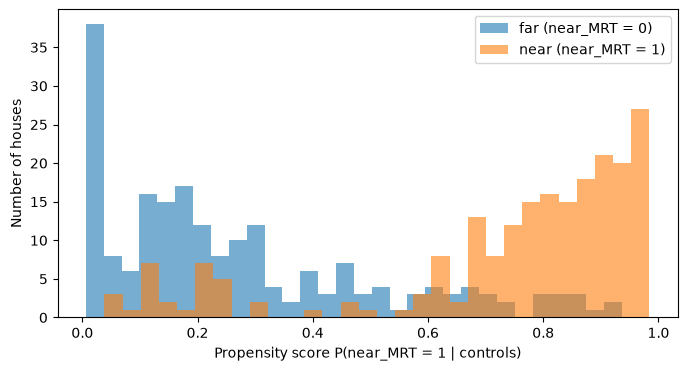

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X = df[controls].values
t = df[treatment].values
y = df[outcome].values

propensity_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
propensity_model.fit(X, t)
p_score = propensity_model.predict_proba(X)[:, 1]

plt.figure(figsize=(8, 4))
plt.hist(p_score[t == 0], bins=30, alpha=0.6, label="far (near_MRT = 0)")
plt.hist(p_score[t == 1], bins=30, alpha=0.6, label="near (near_MRT = 1)")
plt.xlabel("Propensity score P(near_MRT = 1 | controls)")
plt.ylabel("Number of houses")
plt.legend()
plt.show()

In [8]:
low = (p_score < 0.05).sum()
high = (p_score > 0.95).sum()
print(f"Score < 0.05: {low} houses, score > 0.95: {high} houses ({(low + high) / len(df):.0%} of all houses)")

Score < 0.05: 43 houses, score > 0.95: 27 houses (17% of all houses)


Most of the two histograms overlap, so for most houses there are similar houses in the other group. But the tails are thin: around 43 houses have a score below 0.05 and 27 above 0.95 (about 17% of the houses). For these houses the location almost decides if they are near a station, so the estimates depend more on the model guessing. This makes sense because latitude and longitude are almost a proxy for the distance.

# 3. CausalML

The S-learner (LRSRegressor, with linear regression) fits one model with the controls and the treatment, and compares the prediction with treatment = 1 vs treatment = 0. With a linear model, this is just the coefficient of the treatment.

The T-learner (XGBTRegressor, with XGBoost) fits 2 models, one on houses near a station and one on houses far from it. The effect for each house is the difference between the 2 predictions, so the effect can be different for each house.

#### 3.1 LRSRegressor

In [9]:
from causalml.inference.meta import LRSRegressor, XGBTRegressor

lr = LRSRegressor()
te, lb, ub = lr.estimate_ate(X, t, y)
print(f"LRSRegressor  ATE: {te[0]:.2f}  95% CI: [{lb[0]:.2f}, {ub[0]:.2f}]")

LRSRegressor  ATE: 9.36  95% CI: [6.66, 12.07]


#### 3.2 XGBTRegressor

In [10]:
xgb_t = XGBTRegressor(random_state=42)
te, lb, ub = xgb_t.estimate_ate(X, t, y)
print(f"XGBTRegressor ATE: {te[0]:.2f}  95% CI: [{lb[0]:.2f}, {ub[0]:.2f}]")

XGBTRegressor ATE: 9.65  95% CI: [8.32, 10.98]


#### 3.3 Comparing the estimates

In [11]:
ate_lr = lr.estimate_ate(X, t, y)
ate_xgb = xgb_t.estimate_ate(X, t, y)

summary = pd.DataFrame({
    "ATE": [naive_diff, ate_lr[0][0], ate_xgb[0][0]],
    "CI lower": [np.nan, ate_lr[1][0], ate_xgb[1][0]],
    "CI upper": [np.nan, ate_lr[2][0], ate_xgb[2][0]],
}, index=["Naive difference", "LRSRegressor (S-learner, linear)", "XGBTRegressor (T-learner, XGBoost)"])
summary.round(2)

,ATE,CI lower,CI upper
Naive difference,16.84,NaN,NaN
"LRSRegressor (S-learner, linear)",9.36,6.66,12.07
"XGBTRegressor (T-learner, XGBoost)",9.65,8.32,10.98


In [12]:
mean_price = df["Price"].mean()
print(f"Average price: {mean_price:.1f}")
print(f"Effect as share of average price: {ate_lr[0][0] / mean_price:.0%} (LRS), {ate_xgb[0][0] / mean_price:.0%} (XGBT)")


Average price: 38.0
Effect as share of average price: 25% (LRS), 25% (XGBT)


Both models give almost the same result: after controlling for the other features, being less than 500 m from a station increases the price per unit area by about 9.4 to 9.7, and the confidence intervals don't include 0. This is a bit more than half of the naive difference (16.8), so about 40% of the raw difference comes from the near houses being different in other ways.

The XGBoost interval is narrower, but I wouldn't trust that too much since the effects per house are noisy with only about 200 houses per group (see below).

The average price is about 38, so the effect is around 25% of an average price. The unit is 10,000 New Taiwan Dollars per Ping according to the UCI description of the dataset.

#### 3.4 Effect per house and feature importance

The T-learner gives one effect per house. I first look at how these effects are spread, and then which features explain why the effect is bigger for some houses. This feature importance is about the treatment effect, not about the price (that was Assignment 1).

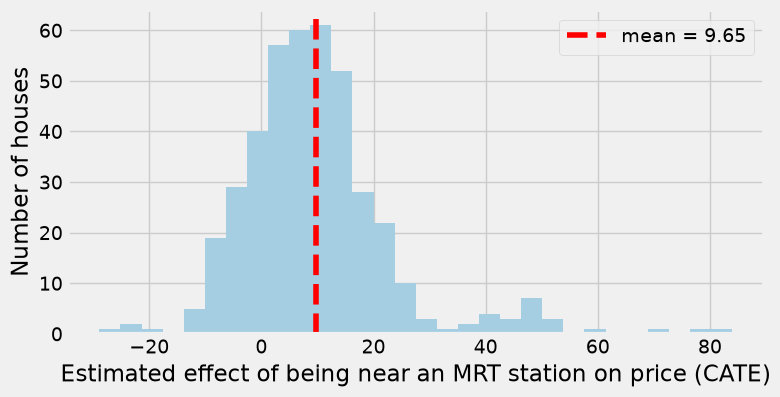

count    414.00
mean       9.65
std       13.73
min      -28.89
25%        1.47
50%        8.26
75%       14.82
max       83.95
dtype: float64

In [13]:
cate_xgb = xgb_t.fit_predict(X, t, y).flatten()

plt.figure(figsize=(8, 4))
plt.hist(cate_xgb, bins=30)
plt.axvline(cate_xgb.mean(), color="red", linestyle="--", label=f"mean = {cate_xgb.mean():.2f}")
plt.xlabel("Estimated effect of being near an MRT station on price (CATE)")
plt.ylabel("Number of houses")
plt.legend()
plt.show()

pd.Series(cate_xgb).describe().round(2)

get_importance and plot_importance train another model that predicts the effect from the features. I tried 2 methods: "auto" (the built-in importance of that model) and "permutation" (how much worse the model gets when a feature is shuffled, on 30% of the data held out).

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

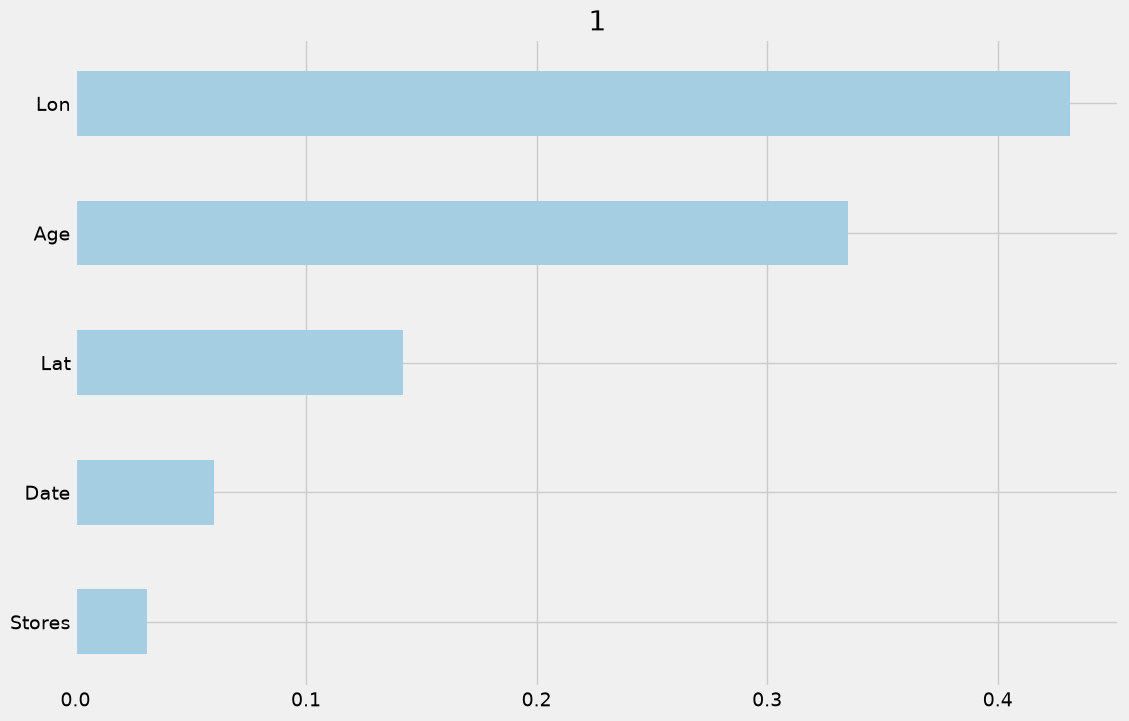

In [14]:
xgb_t.plot_importance(X=X, tau=cate_xgb, normalize=True, method="auto", features=controls)

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

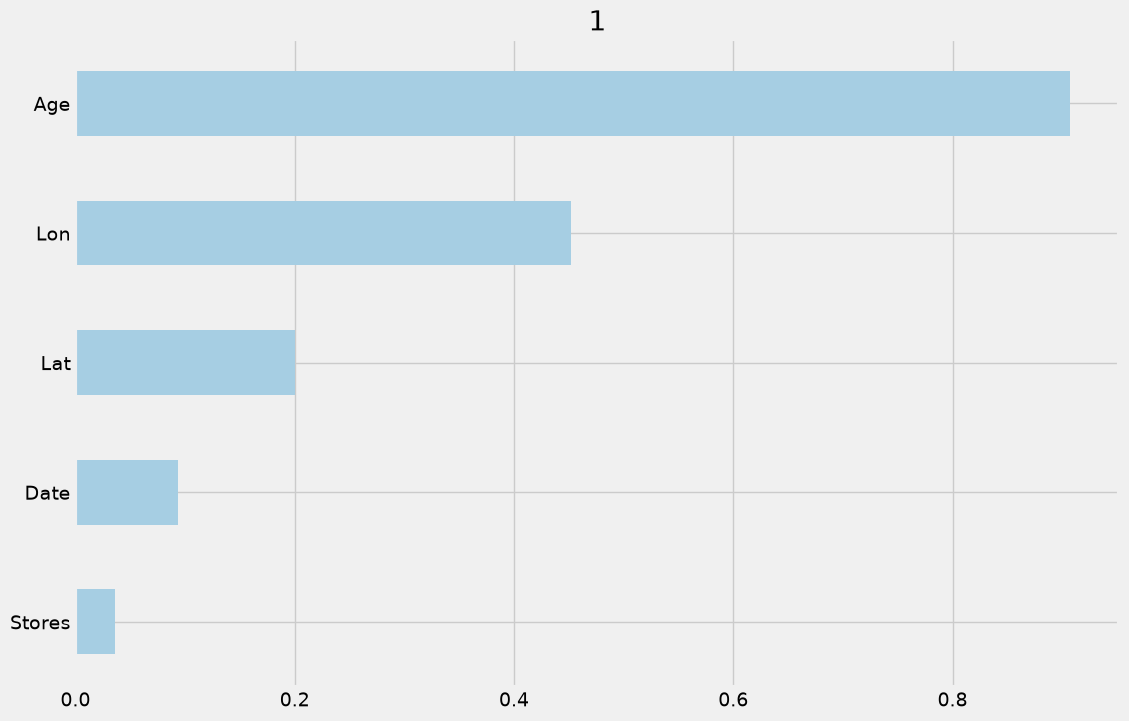

In [15]:
xgb_t.plot_importance(X=X, tau=cate_xgb, method="permutation", features=controls, random_state=42)

SHAP values also show the direction: for each house, if a feature pushes the effect up or down.

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

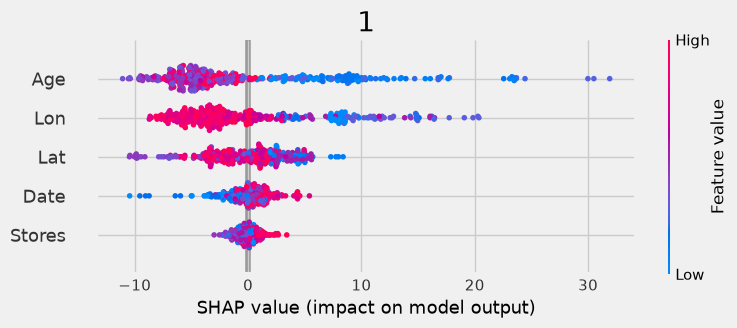

In [16]:
shap_xgb = xgb_t.get_shap_values(X=X, tau=cate_xgb, features=controls)
xgb_t.plot_shap_values(X=X, shap_dict=shap_xgb, features=controls)

In [17]:
print(f"Share of houses with a negative effect: {(cate_xgb < 0).mean():.0%}")

age_groups = pd.cut(df["Age"], bins=[-1, 9, 16, 50], labels=["< 9 years", "9-16 years", "> 16 years"])
pd.Series(cate_xgb).groupby(age_groups).mean().round(2)

Share of houses with a negative effect: 20%


Age
< 9 years     17.46
9-16 years    11.16
> 16 years     5.04
dtype: float64

All three plots show that 'Age' and 'Lon' explain most of the differences in the effect, and 'Stores' and 'Date' explain very little.

- 'Age': in the SHAP plot, young houses (blue) have a bigger effect and old houses (red) a smaller one. When I averaged the effects by age group, houses under 9 years have around 17, and houses older than 16 years only around 4 to 6. So being near a station seems to matter more for newer houses.
- 'Lon': low longitudes (west, blue) have a bigger effect. On the Assignment 1 map, the west is the cheaper area further from the centre, so a station there probably makes more of a difference than in the centre where most houses are already close to transport.
- 'Stores' changes the effect very little, even though it is a strong predictor of the price itself.

About 20% of the houses get a negative effect, and the spread is large (std 13.7). Since the T-learner subtracts 2 models trained on about 200 houses each, a lot of this is probably noise. I trust the general patterns more than the number for a single house.

#### 3.5 Without 'Stores'

Since 'Stores' could be a mediator (see section 2), I run both models again without it.

In [18]:
controls_no_stores = ["Date", "Age", "Lat", "Lon"]
X_ns = df[controls_no_stores].values

rows = []
for name, learner in [("LRSRegressor", LRSRegressor()), ("XGBTRegressor", XGBTRegressor(random_state=42))]:
    te_ns, lb_ns, ub_ns = learner.estimate_ate(X_ns, t, y)
    rows.append([name, te_ns[0], lb_ns[0], ub_ns[0]])
pd.DataFrame(rows, columns=["learner", "ATE (no Stores)", "CI lower", "CI upper"]).round(2)

,learner,ATE (no Stores),CI lower,CI upper
0,LRSRegressor,11.44,9.4,13.48
1,XGBTRegressor,10.56,9.2,11.92


Without 'Stores', the effect goes up to about 10.6 to 11.4. This fits the idea that part of the station effect goes through the stores around the stations, and controlling for 'Stores' removes that part. So the 9.4 from before is more the effect of the station on top of the stores, and the 11 here is closer to the total effect. The data alone can't tell which assumption about 'Stores' is correct.

# 4. DoWhy

DoWhy has 4 steps: model (the assumptions), identify, estimate, and refute.

#### 4.1 CausalModel with common causes

I use one treatment, the outcome, and the same controls as common causes. As the assignment requires, I assume linear relationships.

In [19]:
from dowhy import CausalModel

model = CausalModel(
    data=df,
    treatment=[treatment],
    outcome=outcome,
    common_causes=controls,
)

#### 4.2 View the model

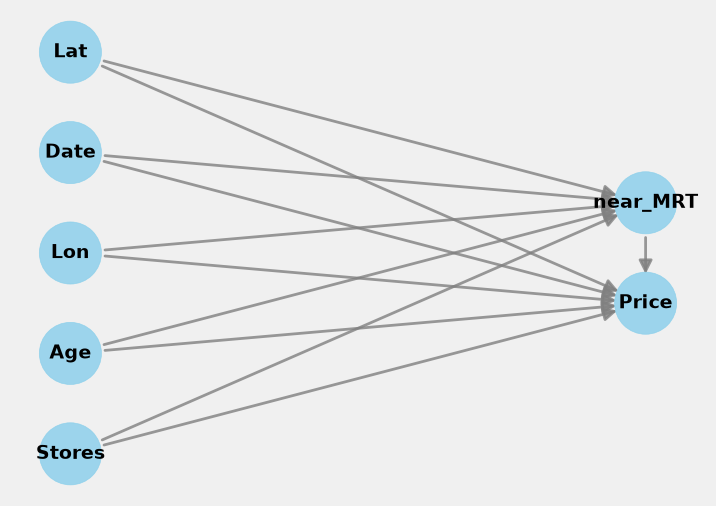

In [20]:
model.view_model()

Each common cause points to both 'near_MRT' and 'Price', and there is the arrow from 'near_MRT' to 'Price' that I want to estimate.

#### 4.3 Identify the effect

In [21]:
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                       
───────────(E[Price|Stores,Age,Lon,Date,Lat])
d[near_MRT]                                  
Estimand assumption 1, Unconfoundedness: If U→{near_MRT} and U→Price then P(Price|near_MRT,Stores,Age,Lon,Date,Lat,U) = P(Price|near_MRT,Stores,Age,Lon,Date,Lat)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!



DoWhy finds a backdoor estimand -> the effect can be found by comparing near and far houses with the same values for the common causes. This only works if there is no other hidden variable that affects both the distance to the station and the price (the unconfoundedness assumption printed above). I didn't give any instruments, so the iv and frontdoor estimands are not available.

#### 4.4 Estimate the effect

I used 2 methods: linear regression (since I assume linearity) and propensity score matching (which doesn't assume a linear model).

In [22]:
estimate_lr = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.linear_regression",
    test_significance=True,
    confidence_intervals=True,
)
print(estimate_lr)

*** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                       
───────────(E[Price|Stores,Age,Lon,Date,Lat])
d[near_MRT]                                  
Estimand assumption 1, Unconfoundedness: If U→{near_MRT} and U→Price then P(Price|near_MRT,Stores,Age,Lon,Date,Lat,U) = P(Price|near_MRT,Stores,Age,Lon,Date,Lat)

## Realized estimand
b: Price~near_MRT+Stores+Age+Lon+Date+Lat
Target units: ate

## Estimate
Mean value: 9.362842568907588
p-value: [2.17239556e-15]
95.0% confidence interval: [[ 7.13268165 11.59300349]]



In [23]:
estimate_psm = model.estimate_effect(
    identified_estimand,
    method_name="backdoor.propensity_score_matching",
)
print(f"Propensity score matching estimate: {estimate_psm.value:.2f}")

Propensity score matching estimate: 9.49


The linear regression gives 9.36 (95% CI from 7.1 to 11.6, p-value very small). It's the same as LRSRegressor, which makes sense since both are a linear regression with the treatment and the controls. Propensity score matching gives 9.49, close to the other estimates. So 4 different methods give between 9.4 and 9.7.

#### 4.5 Refute the estimate

- Placebo treatment: the treatment is replaced by a random shuffle, so the effect should go to about 0.
- Random common cause: a random variable is added as a confounder, so the effect shouldn't change much.
- Data subset: the effect is estimated again on random 80% subsets, so it should stay about the same.

In [24]:
refute_placebo = model.refute_estimate(
    identified_estimand, estimate_lr,
    method_name="placebo_treatment_refuter", placebo_type="permute",
    num_simulations=100, random_seed=42,
)
print(refute_placebo)

Refute: Use a Placebo Treatment
Estimated effect:9.362842568907588
New effect:0.008249637541611036
p value:1.0



In [25]:
refute_rcc = model.refute_estimate(
    identified_estimand, estimate_lr,
    method_name="random_common_cause", num_simulations=100, random_seed=42,
)
print(refute_rcc)

Refute: Add a random common cause
Estimated effect:9.362842568907588
New effect:9.36338318672155
p value:0.8799999999999999



In [26]:
refute_subset = model.refute_estimate(
    identified_estimand, estimate_lr,
    method_name="data_subset_refuter", subset_fraction=0.8,
    num_simulations=100, random_seed=42,
)
print(refute_subset)

Refute: Use a subset of data
Estimated effect:9.362842568907588
New effect:9.163360669912166
p value:0.9



The estimate passes all three:
- Placebo: the effect drops to about 0.01, so the effect really comes from the treatment column.
- Random common cause: the effect doesn't change (9.363 vs 9.363).
- Subset: the effect stays around 9.2, so it doesn't depend on a few houses.

But these tests can't check for a hidden confounder that is not in the data (for example the size of the house, the type of building or the quality of the neighbourhood). Passing them only means the estimate is stable under my assumptions.

#### 4.6 Causal graph

With common causes, every control is assumed to affect both the treatment and the price. With a graph, I can write my assumption about 'Stores' -> location and date affect everything, being near a station leads to more stores, and stores affect the price (near_MRT -> Stores -> Price). I assume 'Age' affects the price but not the distance to a station.

With this graph, DoWhy shouldn't control for 'Stores', so the result should be the total effect.

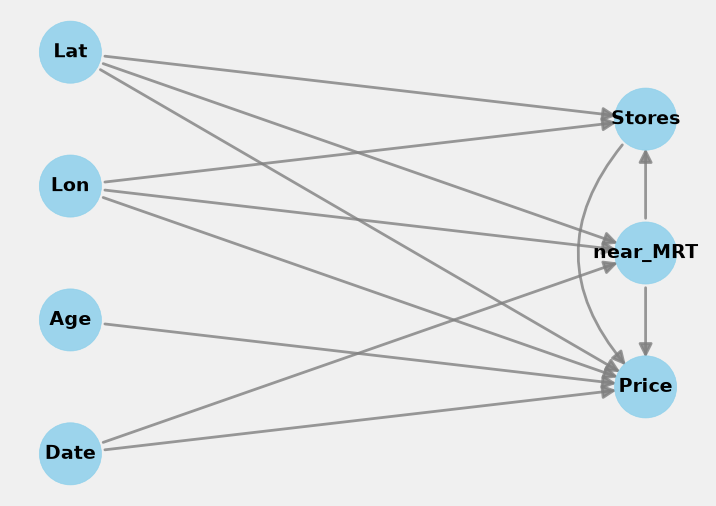

In [27]:
causal_graph = """
digraph {
    Lat -> near_MRT; Lon -> near_MRT; Date -> near_MRT;
    Lat -> Price;    Lon -> Price;    Date -> Price;
    Lat -> Stores;   Lon -> Stores;
    Age -> Price;
    near_MRT -> Stores;
    Stores -> Price;
    near_MRT -> Price;
}
"""

model_graph = CausalModel(
    data=df,
    treatment=treatment,
    outcome=outcome,
    graph=causal_graph,
)
model_graph.view_model()

In [28]:
identified_graph = model_graph.identify_effect(proceed_when_unidentifiable=True)
print(identified_graph)

estimate_graph = model_graph.estimate_effect(
    identified_graph, method_name="backdoor.linear_regression", confidence_intervals=True)
print(f"Total effect of near_MRT (graph interface): {estimate_graph.value:.2f}")
print("95% CI:", np.round(estimate_graph.get_confidence_intervals(), 2))

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                            
───────────(E[Price|Lon,Date,Lat])
d[near_MRT]                       
Estimand assumption 1, Unconfoundedness: If U→{near_MRT} and U→Price then P(Price|near_MRT,Lon,Date,Lat,U) = P(Price|near_MRT,Lon,Date,Lat)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

Total effect of near_MRT (graph interface): 11.57
95% CI: [ 9.6  13.49]


With the graph, DoWhy only controls for 'Lat', 'Lon' and 'Date', because they are the only ones that also affect 'near_MRT'. It leaves out 'Stores' (a mediator in my graph) and 'Age' (it affects price but not the treatment). The effect is 11.57 (CI from 9.6 to 13.5), close to the CausalML results without 'Stores' in 3.5.

So the difference between the two ways is: with common causes I assumed 'Stores' was a confounder, and with the graph I said it was a mediator. The graph is my own assumption, it isn't learned from the data.

#### 4.7 Changing the treatment

I put the DoWhy steps in a function and tried 3 treatments (all binary):
- 'near_MRT': less than 500 m from a station, with Date, Age, Stores, Lat, Lon as common causes
- 'many_stores': 5 or more convenience stores, with Date, Age, MRT_distance, Lat, Lon
- 'new_house': less than 10 years old, with Date, MRT_distance, Stores, Lat, Lon

In [29]:
df["many_stores"] = (df["Stores"] >= 5).astype(int)
df["new_house"] = (df["Age"] < 10).astype(int)

def run_dowhy(data, treat, common_causes, label):
    m = CausalModel(data=data, treatment=[treat], outcome=outcome, common_causes=common_causes)
    est_id = m.identify_effect(proceed_when_unidentifiable=True)
    est = m.estimate_effect(est_id, method_name="backdoor.linear_regression", confidence_intervals=True)
    placebo = m.refute_estimate(est_id, est, method_name="placebo_treatment_refuter",
                                placebo_type="permute", num_simulations=50, random_seed=42)
    ci = np.ravel(est.get_confidence_intervals())
    naive = data.loc[data[treat] == 1, outcome].mean() - data.loc[data[treat] == 0, outcome].mean()
    return {
        "treatment": label,
        "share treated": data[treat].mean(),
        "naive diff": naive,
        "causal estimate": est.value,
        "CI lower": ci[0],
        "CI upper": ci[1],
        "placebo effect": placebo.new_effect,
    }

experiments = [
    ("near_MRT", ["Date", "Age", "Stores", "Lat", "Lon"], "near MRT (< 500 m)"),
    ("many_stores", ["Date", "Age", "MRT_distance", "Lat", "Lon"], "5+ convenience stores"),
    ("new_house", ["Date", "MRT_distance", "Stores", "Lat", "Lon"], "house age < 10 years"),
]
results = pd.DataFrame([run_dowhy(df, tr, cc, lab) for tr, cc, lab in experiments]).set_index("treatment")
results.round(2)

,share treated,naive diff,causal estimate,CI lower,CI upper,placebo effect
treatment,,,,,,
near MRT (< 500 m),0.51,16.84,9.36,7.13,11.59,0.05
5+ convenience stores,0.48,15.63,7.60,5.51,9.69,0.07
house age < 10 years,0.26,11.75,7.93,5.97,9.89,0.07


- Near MRT: the biggest effect, 9.4, about 56% of the naive difference.
- 5+ stores: 7.6 after controlling for the distance to the MRT and the location, about half of the naive difference (15.6). Stores and stations are strongly linked, so a big part of the raw "store effect" was actually the station and the location.
- New house: 7.9, about two thirds of the naive difference. Age is the least confounded, since new and old houses are less different in location than near and far houses.

For all three, the placebo effect is close to 0, so each estimate is linked to its treatment. The confidence intervals overlap, so I can't really say one factor matters more than the others. Also, the effects depend on the cut-offs I chose (500 m, 5 stores, 10 years).

# 5. Conclusion

Hypothesis: being close to an MRT station (less than 500 m) causes a higher price per unit area, even after taking into account the location, the age, the date and the number of stores. In Assignment 1 the distance to the station was the most correlated feature with price, so I wanted to see how much of it is causal.

Results: the data support the hypothesis, but the effect is smaller than what the simple comparison shows. The naive difference is 16.8. With 'Stores' as a control, all methods give about 9.4 to 9.7 (LRSRegressor 9.4, XGBTRegressor 9.7, DoWhy linear regression 9.4, propensity score matching 9.5). Without 'Stores', or with the causal graph, it goes up to about 10.6 to 11.6. So about 40% of the naive difference comes from other differences between near and far houses, and around 2 points of the station effect seem to go through the stores around the stations.

The effect isn't the same for every house: it seems bigger for newer houses and for houses in the west, further from the centre. The other treatments also have positive effects (7.6 for 5+ stores and 7.9 for houses under 10 years), but the confidence intervals overlap. The main estimate passed the placebo, random common cause and subset refuters.

Limitations:
- I assume there is no hidden confounder, but the dataset has no information on the size of the house, the type of building or the neighbourhood, which could affect both the distance to a station and the price. The refuters can't detect this.
- The overlap is weak for about 17% of the houses, where the location almost decides if they are near a station.
- The treatment is a cut-off on a continuous variable, so the result depends on the 500 m I chose.
- With 414 houses, the effect for each single house is noisy, so the averages are more reliable.
- The DoWhy estimates assume linearity, but the XGBoost model and the matching give almost the same numbers, so this assumption doesn't seem to change the result much.

In short, being less than 500 m from a station adds roughly 9 to 12 to the price per unit area (about a quarter of the average price), not the 17 a simple comparison suggests, and it seems to matter most for newer houses further from the centre.